In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Data Preprocessing

## Objective
Prepare the cleaned datasets for further business analysis, SQL analysis, and dashboard development.

This stage focuses on data integration, feature creation, aggregation, data type validation, and preparing analysis-ready datasets while preserving the cleaned source data.

In [34]:
customers=pd.read_csv("../data/processed/customers_clean.csv")
geolocation=pd.read_csv("../data/processed/geolocation_clean.csv",dtype={"geolocation_zip_code_prefix": "str"})
order_payment=pd.read_csv("../data/processed/order_payments_clean.csv")
order_reviews=pd.read_csv("../data/processed/order_reviews_clean.csv")
orders=pd.read_csv("../data/processed/orders_clean.csv")
order_items=pd.read_csv("../data/processed/orders_items_clean.csv")
product_category_name_translation=pd.read_csv("../data/processed/product_category_name_translation_clean.csv")
products=pd.read_csv("../data/processed/products_clean.csv")
sellers=pd.read_csv("../data/processed/sellers_clean.csv", dtype={"seller_zip_code_prefix": "str"})

In [35]:
print("orders shape:",orders.shape)
print("orders data types:\n",orders.dtypes)

orders shape: (99441, 13)
orders data types:
 order_id                              str
customer_id                           str
order_status                          str
order_purchase_timestamp              str
order_approved_at                     str
order_delivered_carrier_date          str
order_delivered_customer_date         str
order_estimated_delivery_date         str
invalid_delivery_date                bool
canceled_with_delivery_date          bool
delivered_without_approval           bool
invalid_approval_carrier_sequence    bool
invalid_carrier_customer_sequence    bool
dtype: object


In [36]:
date_col=["order_purchase_timestamp","order_approved_at","order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date"]
for col in date_col:
    orders[col]=pd.to_datetime(orders[col],errors="coerce")

In [37]:
print(order_items.shape)
print(order_items.dtypes)

(112650, 7)
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object


In [38]:
order_items["shipping_limit_date"]=pd.to_datetime(order_items["shipping_limit_date"])

In [39]:
print(customers.shape)
print(customers.dtypes)

(99441, 5)
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object


In [40]:
print(order_payment.shape)
print(order_payment.dtypes)

(103886, 5)
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object


In [41]:
print(order_reviews.shape)
print(order_reviews.dtypes)

(99224, 7)
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str
dtype: object


In [42]:
order_reviews["review_answer_timestamp"]=pd.to_datetime(order_reviews["review_answer_timestamp"])
order_reviews["review_creation_date"]=pd.to_datetime(order_reviews["review_creation_date"])

In [43]:
print(products.shape)
print(products.dtypes)

(32951, 9)
product_id                        str
product_category_name             str
product_name_length           float64
product_description_length    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object


In [44]:
print(sellers.shape)
print(sellers.dtypes)

(3095, 4)
seller_id                 str
seller_zip_code_prefix    str
seller_city               str
seller_state              str
dtype: object


In [45]:
print(geolocation.shape)
print(geolocation.dtypes)

(738332, 6)
geolocation_zip_code_prefix        str
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
invalid_brazil_coords             bool
dtype: object


In [46]:
print(product_category_name_translation.shape)
print(product_category_name_translation.dtypes)

(71, 2)
product_category_name            str
product_category_name_english    str
dtype: object


In [47]:
product_category_name_translation

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
...,...,...
66,flores,flowers
67,artes_e_artesanato,arts_and_craftmanship
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes


In [48]:
products["product_category_name"].isnull().sum()

np.int64(610)

In [49]:
missing_translation = set(products["product_category_name"].dropna().unique()) - set(
    product_category_name_translation["product_category_name"]
)

len(missing_translation)

2

In [50]:
missing_translation

{'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

In [51]:
additional_translations = pd.DataFrame({
    "product_category_name": [
        "pc_gamer",
        "portateis_cozinha_e_preparadores_de_alimentos"
    ],
    "product_category_name_english": [
        "gaming_pcs",
        "kitchen_appliances_and_food_processors"
    ]
})

product_category_name_translation = pd.concat(
    [product_category_name_translation, additional_translations],
    ignore_index=True
)

In [52]:
product_category_name_translation["product_category_name"].duplicated().sum()

np.int64(0)

In [53]:
products=products.merge(product_category_name_translation,on="product_category_name",how='left')

In [54]:
products.shape

(32951, 10)

In [55]:
products["product_category_name_english"].isnull().sum()

np.int64(610)

In [56]:
products[products["product_category_name"].isin(["pc_gamer","portateis_cozinha_e_preparadores_de_alimentos"])][["product_category_name","product_category_name_english"]].drop_duplicates()

,product_category_name,product_category_name_english
1628,pc_gamer,gaming_pcs
5821,portateis_cozinha_e_preparadores_de_alimentos,kitchen_appliances_and_food_processors


In [57]:
products["product_category_name_english"] = (
    products["product_category_name_english"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", "_", regex=True)
)

In [58]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence'],
      dtype='str')

In [59]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [60]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_length',
       'product_description_length', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name_english'],
      dtype='str')

In [61]:
selected_orders=orders[["order_id","customer_id","order_status","order_purchase_timestamp"]]
selected_orders_items=order_items.copy()
selected_products=products[["product_id","product_category_name_english"]]

In [62]:
selected_orders.shape

(99441, 4)

In [63]:
selected_orders_items.shape

(112650, 7)

In [64]:
selected_products.shape

(32951, 2)

In [65]:
sales_items=selected_orders_items.merge(selected_products,on="product_id",how="left")

In [67]:
sales_items.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,garden_tools
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,housewares
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,telephony
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,garden_tools
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,health_beauty
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,books_technical


In [68]:
sales_items.shape

(112650, 8)

In [69]:
sales_items["product_category_name_english"].isnull().sum()

np.int64(1603)

In [70]:
sales_items["product_id"].isnull().sum()

np.int64(0)

In [71]:
sales_analysis=sales_items.merge(selected_orders,on="order_id",how="left")

In [72]:
sales_analysis.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,customer_id,order_status,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,furniture_decor,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumery,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,garden_tools,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,housewares,816cbea969fe5b689b39cfc97a506742,delivered,2017-05-15 21:42:34
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,telephony,32e2e6ab09e778d99bf2e0ecd4898718,delivered,2017-12-10 11:53:48
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,garden_tools,9ed5e522dd9dd85b4af4a077526d8117,delivered,2018-07-04 12:08:27
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,health_beauty,16150771dfd4776261284213b89c304e,delivered,2018-03-19 18:40:33
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,books_technical,351d3cb2cee3c7fd0af6616c82df21d3,delivered,2018-07-02 13:59:39


In [73]:
sales_analysis.shape

(112650, 11)

In [74]:
sales_analysis["customer_id"].isnull().sum()

np.int64(0)

In [75]:
sales_analysis["order_status"].isnull().sum()

np.int64(0)

In [77]:
sales_analysis["order_purchase_timestamp"].isnull().sum()

np.int64(0)

### Sales Analysis Dataset

- Integrated Orders, Order Items, and Products datasets.
- Added English product category information.
- Used left joins to preserve all order-item records.
- Verified that the final dataset contains 112,650 rows and 11 columns.
- Confirmed that all order items matched their corresponding orders and products.
- Retained 1,603 missing product categories because the original category information was unavailable.

In [78]:
sales_analysis.to_csv("../data/processed/sales_analysis.csv",index=False)

In [79]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [81]:
selected_customers=customers.copy()
selected_customers.shape

(99441, 5)

In [ ]:
sales_analysis["customer_id"].isnull().sum()

np.int64(0)

In [85]:
customer_analysis=selected_orders.merge(selected_customers,on="customer_id",how="left")

In [87]:
customer_analysis.shape

(99441, 8)

In [88]:
customer_analysis["customer_unique_id"].isnull().sum()

np.int64(0)

In [89]:
customer_analysis["customer_city"].isnull().sum()

np.int64(0)

In [90]:
customer_analysis["customer_state"].isnull().sum()

np.int64(0)

### Customer Analysis Dataset

- Integrated Orders and Customers datasets using a left join on customer_id.
- Included customer_unique_id to identify actual customers across multiple orders.
- Added customer geographic information, including ZIP code, city, and state.
- Verified that all 99,441 order records were preserved.
- Confirmed that no customer IDs or geographic fields were missing.

In [91]:
customer_analysis.to_csv("../data/processed/customer_analysis.csv",index=False)

In [92]:
order_payment.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='str')

In [94]:
selected_payments = order_payment.copy()

In [95]:
selected_payments.shape

(103886, 5)

In [96]:
payment_analysis=selected_orders.merge(selected_payments,on="order_id",how="left")

In [98]:
payment_analysis.shape

(103887, 8)

In [100]:
payment_analysis["payment_installments"].isnull().sum()

np.int64(1)

In [101]:
selected_orders["order_id"].duplicated().sum()

np.int64(0)

In [102]:
selected_payments["order_id"].duplicated().sum()

np.int64(4446)

In [103]:
selected_payments["order_id"].isin(
    selected_orders["order_id"]
).value_counts()

order_id
True    103886
Name: count, dtype: int64

In [104]:
payment_analysis["payment_value"].isna().sum()

np.int64(1)

In [105]:
payment_analysis.loc[
    payment_analysis["payment_value"].isna(),
    ["order_id", "order_status"]
]

,order_id,order_status
32133,bfbd0f9bdef84302105ad712db648a6c,delivered


In [107]:
order_payment[
    order_payment["order_id"] == "bfbd0f9bdef84302105ad712db648a6c"
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value


### Payment Analysis Dataset

- Integrated Orders and Payments datasets using a left join on order_id.
- Preserved all order records and their associated payment details.
- Retained multiple payment records for orders with split payments.
- Verified that all payment records matched existing orders.
- Identified one delivered order without a corresponding payment record in the original Payments dataset.
- Retained the missing payment information rather than removing the order.

In [108]:
payment_analysis.to_csv("../data/processed/payment_analysis.csv",index=False)

In [109]:
order_reviews.columns

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='str')

In [110]:
selected_reviews = order_reviews[["order_id","review_score"]].copy()

In [111]:
selected_reviews.shape

(99224, 2)

In [112]:
review_analysis=selected_orders.merge(selected_reviews,on="order_id",how="left")

In [116]:
review_analysis["review_score"].isna().sum()

np.int64(768)

In [113]:
review_analysis.shape

(99992, 5)

In [115]:
selected_reviews["order_id"].duplicated().sum()

np.int64(551)

In [117]:
selected_reviews[
    selected_reviews["order_id"].duplicated(keep=False) &
    selected_reviews["order_id"].notna()
].sort_values("order_id").head(10)

,order_id,review_score
25612,0035246a40f520710769010f752e7507,5
22423,0035246a40f520710769010f752e7507,5
22779,013056cfe49763c6f66bda03396c5ee3,5
68633,013056cfe49763c6f66bda03396c5ee3,4
854,0176a6846bcb3b0d3aa3116a9a768597,5
83224,0176a6846bcb3b0d3aa3116a9a768597,5
17582,02355020fd0a40a0d56df9f6ff060413,1
89888,02355020fd0a40a0d56df9f6ff060413,3
55137,029863af4b968de1e5d6a82782e662f5,4
37911,029863af4b968de1e5d6a82782e662f5,5


In [118]:
review_analysis["review_score"].isna().sum()

np.int64(768)

In [119]:
review_analysis["order_id"].isna().sum()

np.int64(0)

In [120]:
review_analysis.loc[
    review_analysis["review_score"].isna(),
    ["order_id", "order_status"]
].head(10)

,order_id,order_status
16,403b97836b0c04a622354cf531062e5f,delivered
154,6942b8da583c2f9957e990d028607019,shipped
311,4906eeadde5f70b308c20c4a8f20be02,delivered
382,b7a4a9ecb1cd3ef6a3e36a48e200e3be,delivered
390,59b32faedc12322c672e95ec3716d614,delivered
410,c2215076050fa358934105b15c34cf3b,delivered
537,eafef0e6c44f121531569a69a318c3b3,delivered
838,95d9d2979d40161be87292ff88563cba,delivered
840,a9b151f0c0471d9b2534fa73c9c0e123,delivered
1047,5e8d0f2f1e06e715aee3eefe4c175e52,delivered


In [121]:
selected_reviews["review_score"].value_counts(dropna=False).sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

### Review Analysis Dataset

- Integrated Orders and Reviews datasets using a left join on order_id.
- Included review scores to support customer satisfaction analysis.
- Retained multiple review records associated with the same order.
- Preserved all order records, including orders without matching reviews.
- Identified 768 orders without a matching review and retained their missing review scores.
- Validated that all available review scores are within the range of 1 to 5.

In [122]:
review_analysis.to_csv("../data/processed/review_analysis.csv",index=False)

In [123]:
sellers.columns

Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'],
      dtype='str')

In [124]:
selected_sellers=sellers.copy()

In [125]:
selected_sellers.shape

(3095, 4)

In [126]:
seller_analysis=sales_items.merge(selected_sellers,on="seller_id",how="left")  

In [127]:
seller_analysis.shape

(112650, 11)

In [128]:
seller_analysis["seller_city"].isna().sum()

np.int64(0)

In [129]:
seller_analysis["seller_state"].isna().sum()

np.int64(0)

In [130]:
seller_analysis["seller_zip_code_prefix"].isna().sum()

np.int64(0)

### Seller Analysis Dataset

- Integrated Order Items and Sellers datasets using a left join on seller_id.
- Added seller geographic information, including ZIP code, city, and state.
- Preserved all 112,650 order-item records.
- Verified that all order items matched their corresponding seller records.
- Confirmed that no seller geographic information was missing.

In [198]:
seller_analysis.to_csv("../data/processed/seller_analysis.csv",index=False)

In [132]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence'],
      dtype='str')

In [133]:
selected_delivery_orders=orders.copy()

In [134]:
selected_delivery_orders.shape

(99441, 13)

In [135]:
selected_delivery_items=order_items[["order_id","order_item_id","seller_id","shipping_limit_date"]]

In [136]:
selected_delivery_items.shape

(112650, 4)

In [137]:
delivery_analysis=selected_delivery_orders.merge(selected_delivery_items,on="order_id",how="left")

In [138]:
delivery_analysis.shape

(113425, 16)

In [139]:
delivery_analysis["order_item_id"].isna().sum()

np.int64(775)

In [140]:
delivery_analysis["shipping_limit_date"].isna().sum()

np.int64(775)

In [141]:
delivery_analysis.loc[
    delivery_analysis["order_item_id"].isna(),
    "order_status"
].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [142]:
delivery_analysis.loc[
    delivery_analysis["order_item_id"].isna() &
    (delivery_analysis["order_status"] == "shipped"),
    ["order_id", "order_status"]
]

,order_id,order_status
26478,a68ce1686d536ca72bd2dadc4b8671e5,shipped


In [143]:
delivery_analysis.loc[
    delivery_analysis["order_id"] == "a68ce1686d536ca72bd2dadc4b8671e5",
    [
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
26478,shipped,2016-10-05 01:47:40,2016-10-07 03:11:22,2016-11-07 16:37:37,NaT,2016-12-01


In [144]:
delivery_analysis[
    [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].isna().sum()

order_purchase_timestamp            0
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_estimated_delivery_date       0
dtype: int64

In [145]:
delivery_analysis.groupby("order_status")[
    [
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].apply(lambda x: x.isna().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,3,3
canceled,141,630,699
created,5,5,5
delivered,15,2,8
invoiced,0,361,361
processing,0,357,357
shipped,0,0,1186
unavailable,0,610,610


In [146]:
delivery_analysis=delivery_analysis.merge(selected_sellers,on="seller_id",how="left")

In [147]:
delivery_analysis.shape

(113425, 19)

In [148]:
delivery_analysis["seller_city"].isnull().sum()

np.int64(775)

In [149]:
delivery_analysis["seller_state"].isnull().sum()

np.int64(775)

In [150]:
delivery_analysis["seller_zip_code_prefix"].isnull().sum()

np.int64(775)

In [151]:
delivery_analysis=delivery_analysis.merge(selected_customers,on="customer_id",how="left")

In [152]:
delivery_analysis.shape

(113425, 23)

In [154]:
delivery_analysis[["customer_zip_code_prefix","customer_city","customer_state"]].isnull().sum()

customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [157]:
delivery_analysis["actual_delivery_days"]=(delivery_analysis["order_delivered_customer_date"]-delivery_analysis["order_purchase_timestamp"]).dt.days

In [159]:
delivery_analysis["actual_delivery_days"].describe()

count    110196.000000
mean         12.007723
std           9.451455
min           0.000000
25%           6.000000
50%          10.000000
75%          15.000000
max         209.000000
Name: actual_delivery_days, dtype: float64

In [160]:
delivery_analysis["delivery_delay_days"]=(delivery_analysis["order_delivered_customer_date"]-delivery_analysis["order_estimated_delivery_date"]).dt.days

In [161]:
delivery_analysis["delivery_delay_days"].describe()

count    110196.000000
mean        -12.030201
std          10.160157
min        -147.000000
25%         -17.000000
50%         -13.000000
75%          -7.000000
max         188.000000
Name: delivery_delay_days, dtype: float64

In [165]:
delivery_analysis["purchase_to_approval_hours"]=(delivery_analysis["order_approved_at"]-delivery_analysis["order_purchase_timestamp"]).dt.total_seconds()/3600

In [167]:
delivery_analysis["purchase_to_approval_hours"].describe()

count    113264.000000
mean         10.663526
std          26.228787
min           0.000000
25%           0.216389
50%           0.350556
75%          15.244306
max        4509.180556
Name: purchase_to_approval_hours, dtype: float64

In [168]:
delivery_analysis["Approval-to-carrier time"]=(delivery_analysis["order_delivered_carrier_date"]-delivery_analysis["order_approved_at"]).dt.total_seconds()/3600

In [170]:
delivery_analysis=delivery_analysis.rename(columns={"Approval-to-carrier time":"approval_to_carrier_hours"})

In [172]:
delivery_analysis["approval_to_carrier_hours"].describe()

count    111442.000000
mean         68.426381
std          86.162814
min       -4109.256111
25%          21.193958
50%          44.124306
75%          87.383889
max        3018.301667
Name: approval_to_carrier_hours, dtype: float64

In [182]:
delivery_analysis[delivery_analysis["approval_to_carrier_hours"]>=0]["approval_to_carrier_hours"].describe()

count    109891.000000
mean         69.741584
std          85.077220
min           0.004167
25%          21.815278
50%          44.894722
75%          88.302361
max        3018.301667
Name: approval_to_carrier_hours, dtype: float64

In [183]:

delivery_analysis["carrier_to_customer_hours"] = (delivery_analysis["order_delivered_customer_date"]- delivery_analysis["order_delivered_carrier_date"]).dt.total_seconds() / 3600


In [ ]:


duration_columns = [
    "actual_delivery_days",
    "purchase_to_approval_hours",
    "approval_to_carrier_hours",
    "carrier_to_customer_hours",
]

for column in duration_columns:
    delivery_analysis.loc[
        delivery_analysis[column] < 0, column
    ] = np.nan


In [187]:

duration_columns = [
    "actual_delivery_days",
    "delivery_delay_days",
    "purchase_to_approval_hours",
    "approval_to_carrier_hours",
    "carrier_to_customer_hours"
]

delivery_analysis[duration_columns].isna().sum()


actual_delivery_days          3229
delivery_delay_days           3229
purchase_to_approval_hours     161
approval_to_carrier_hours     3534
carrier_to_customer_hours     3280
dtype: int64

In [188]:

delivery_analysis[
    [
        "actual_delivery_days",
        "purchase_to_approval_hours",
        "approval_to_carrier_hours",
        "carrier_to_customer_hours"
    ]
].lt(0).sum()


actual_delivery_days          0
purchase_to_approval_hours    0
approval_to_carrier_hours     0
carrier_to_customer_hours     0
dtype: int64

In [189]:
delivery_analysis["delivery_delay_days"].lt(0).sum()

np.int64(101481)

In [190]:
delivery_analysis.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence', 'order_item_id', 'seller_id',
       'shipping_limit_date', 'seller_zip_code_prefix', 'seller_city',
       'seller_state', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state', 'actual_delivery_days',
       'delivery_delay_days', 'purchase_to_approval_hours',
       'approval_to_carrier_hours', 'carrier_to_customer_hours'],
      dtype='str')

In [193]:
delivery_analysis["order_id"].duplicated().sum()

np.int64(13984)

In [194]:
delivery_analysis["order_item_id"].duplicated().sum()

np.int64(113403)

In [195]:

delivery_analysis.duplicated(
    subset=["order_id", "order_item_id"]
).sum()


np.int64(0)

### Delivery Duration Feature Validation

- Created delivery duration features using the original order timestamps.
- Converted negative actual delivery durations to missing values.
- Retained negative delivery delays because they represent orders delivered earlier than estimated.
- Converted negative purchase-to-approval, approval-to-carrier, and carrier-to-customer durations to missing values.
- Preserved valid extreme delivery durations and other genuine outliers.
- Retained original timestamps and validation flags for data traceability.
- Verified that no negative values remain in the four duration features where negative values are invalid.

In [197]:
delivery_analysis.to_csv("../data/processed/delivery_analysis.csv",index=False)

In [199]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_length',
       'product_description_length', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name_english'],
      dtype='str')

In [200]:
selected_products = products[["product_id","product_category_name_english","product_photos_qty","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]].copy()

In [201]:
selected_products.shape


(32951, 7)

In [202]:
selected_products["product_id"].duplicated().sum()

np.int64(0)

In [203]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [205]:
selected_products["product_volume_cm3"] = (selected_products["product_length_cm"] *selected_products["product_height_cm"] *selected_products["product_width_cm"])

In [206]:
selected_products[["product_id","product_length_cm","product_height_cm","product_width_cm","product_volume_cm3"]].head()

,product_id,product_length_cm,product_height_cm,product_width_cm,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,16.0,10.0,14.0,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,30.0,18.0,20.0,10800.0
2,96bd76ec8810374ed1b65e291975717f,18.0,9.0,15.0,2430.0
3,cef67bcfe19066a932b7673e239eb23d,26.0,4.0,26.0,2704.0
4,9dc1a7de274444849c219cff195d0b71,20.0,17.0,13.0,4420.0


In [207]:
selected_products[[
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_volume_cm3"
]].isnull().sum()

product_length_cm     2
product_height_cm     2
product_width_cm      2
product_volume_cm3    2
dtype: int64

In [208]:
selected_products["product_volume_cm3"].describe()

count     32949.000000
mean      16564.096695
std       27057.041650
min         168.000000
25%        2880.000000
50%        6840.000000
75%       18480.000000
max      296208.000000
Name: product_volume_cm3, dtype: float64

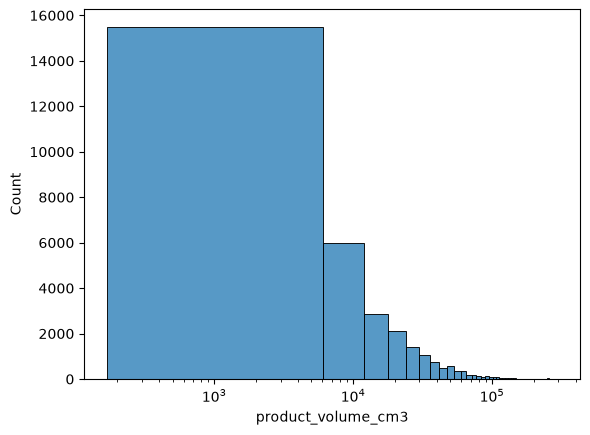

In [211]:
sns.histplot(x=selected_products["product_volume_cm3"],bins=50)
plt.xscale("log")

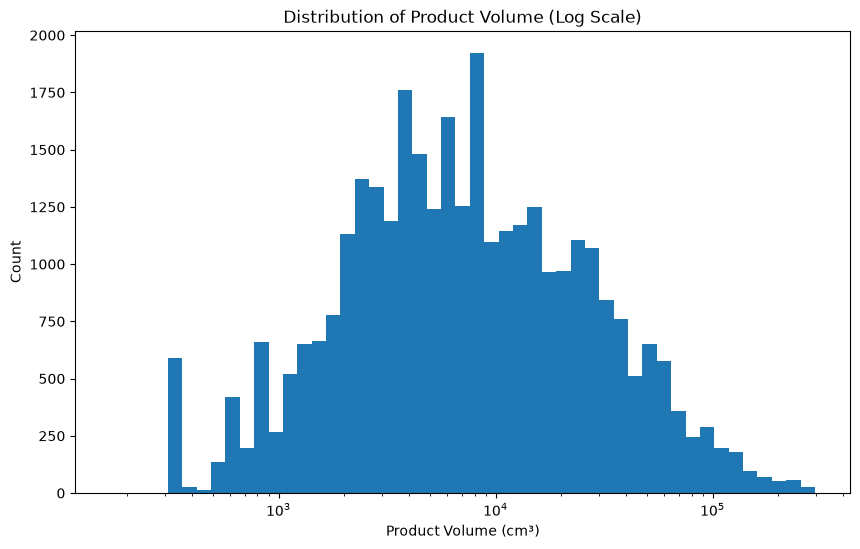

In [212]:
values = selected_products["product_volume_cm3"].dropna()

bins = np.logspace(
    np.log10(values.min()),
    np.log10(values.max()),
    50
)

plt.figure(figsize=(10, 6))
plt.hist(values, bins=bins)
plt.xscale("log")
plt.xlabel("Product Volume (cm³)")
plt.ylabel("Count")
plt.title("Distribution of Product Volume (Log Scale)")
plt.show()

In [213]:
measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_volume_cm3"
]

selected_products[measurement_columns].lt(0).sum()

product_weight_g      0
product_length_cm     0
product_height_cm     0
product_width_cm      0
product_volume_cm3    0
dtype: int64

In [214]:
selected_products.isnull().sum()

product_id                         0
product_category_name_english    610
product_photos_qty               610
product_weight_g                   2
product_length_cm                  2
product_height_cm                  2
product_width_cm                   2
product_volume_cm3                 2
dtype: int64

In [215]:
selected_products.dtypes

product_id                           str
product_category_name_english        str
product_photos_qty               float64
product_weight_g                 float64
product_length_cm                float64
product_height_cm                float64
product_width_cm                 float64
product_volume_cm3               float64
dtype: object

In [216]:
product_analysis = order_items.merge(selected_products,on="product_id",how="left")

In [218]:
product_analysis.shape

(112650, 14)

In [219]:
product_analysis.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name_english', 'product_photos_qty',
       'product_weight_g', 'product_length_cm', 'product_height_cm',
       'product_width_cm', 'product_volume_cm3'],
      dtype='str')

In [220]:
product_analysis["product_category_name_english"].isnull().sum()

np.int64(1603)

In [221]:
product_analysis.to_csv("../data/processed/product_analysis.csv",index=False)

### Product Analysis Dataset

- Integrated Order Items and Products datasets using a left join on `product_id`.
- Added English product categories, product photos, weight, and dimensions.
- Created an engineered feature, `product_volume_cm3`, using product length, height, and width.
- Preserved all 112,650 order-item records.
- Retained missing product attributes without arbitrary imputation.
- Saved the final dataset as `product_analysis.csv` in `data/processed`.

In [222]:
import os

os.listdir("../data/processed")

['customers_clean.csv',
 'customer_analysis.csv',
 'delivery_analysis.csv',
 'geolocation_clean.csv',
 'orders_clean.csv',
 'orders_items_clean.csv',
 'order_payments_clean.csv',
 'order_reviews_clean.csv',
 'payment_analysis.csv',
 'products_clean.csv',
 'product_analysis.csv',
 'product_category_name_translation_clean.csv',
 'review_analysis.csv',
 'sales_analysis.csv',
 'sellers_clean.csv',
 'seller_analysis.csv']

In [223]:
analysis_datasets = {
    "Sales": sales_analysis,
    "Customer": customer_analysis,
    "Payment": payment_analysis,
    "Review": review_analysis,
    "Seller": seller_analysis,
    "Delivery": delivery_analysis,
    "Product": product_analysis
}

for name, df in analysis_datasets.items():
    print(f"{name}: {df.shape}")

Sales: (112650, 11)
Customer: (99441, 8)
Payment: (103887, 8)
Review: (99992, 5)
Seller: (112650, 11)
Delivery: (113425, 28)
Product: (112650, 14)


In [224]:
for name, df in analysis_datasets.items():
    print(f"\n{name}:")
    print(df.columns.tolist())


Sales:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name_english', 'customer_id', 'order_status', 'order_purchase_timestamp']

Customer:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Payment:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Review:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'review_score']

Seller:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name_english', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Delivery:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_d

In [225]:
sales_analysis.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [226]:
customer_analysis["order_id"].duplicated().sum()

np.int64(0)

In [227]:
payment_analysis.duplicated(
    subset=["order_id", "payment_sequential"]
).sum()

np.int64(0)

In [228]:
seller_analysis.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [229]:
delivery_analysis.dropna(
    subset=["order_item_id"]
).duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [230]:
product_analysis.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [231]:
for name, df in analysis_datasets.items():
    print(f"\n{name}:")
    print(df.isnull().sum()[df.isnull().sum() > 0])


Sales:
product_category_name_english    1603
dtype: int64

Customer:
Series([], dtype: int64)

Payment:
payment_sequential      1
payment_type            1
payment_installments    1
payment_value           1
dtype: int64

Review:
review_score    768
dtype: int64

Seller:
product_category_name_english    1603
dtype: int64

Delivery:
order_approved_at                 161
order_delivered_carrier_date     1968
order_delivered_customer_date    3229
order_item_id                     775
seller_id                         775
shipping_limit_date               775
seller_zip_code_prefix            775
seller_city                       775
seller_state                      775
actual_delivery_days             3229
delivery_delay_days              3229
purchase_to_approval_hours        161
approval_to_carrier_hours        3534
carrier_to_customer_hours        3280
dtype: int64

Product:
product_category_name_english    1603
product_photos_qty               1603
product_weight_g                  

In [232]:
delivery_analysis[[
    "actual_delivery_days",
    "delivery_delay_days",
    "purchase_to_approval_hours",
    "approval_to_carrier_hours",
    "carrier_to_customer_hours"
]].describe()

,actual_delivery_days,delivery_delay_days,purchase_to_approval_hours,approval_to_carrier_hours,carrier_to_customer_hours
count,110196.000000,110196.000000,113264.000000,109891.000000,110145.000000
mean,12.007723,-12.030201,10.663526,69.741584,220.653356
std,9.451455,10.160157,26.228787,85.077220,206.948834
min,0.000000,-147.000000,0.000000,0.004167,0.000000
25%,6.000000,-17.000000,0.216389,21.815278,97.510278
50%,10.000000,-13.000000,0.350556,44.894722,169.446944
75%,15.000000,-7.000000,15.244306,88.302361,285.941389
max,209.000000,188.000000,4509.180556,3018.301667,4924.583333


In [233]:
delivery_analysis[[
    "invalid_delivery_date",
    "canceled_with_delivery_date",
    "delivered_without_approval",
    "invalid_approval_carrier_sequence",
    "invalid_carrier_customer_sequence"
]].sum()

invalid_delivery_date                 544
canceled_with_delivery_date             7
delivered_without_approval             15
invalid_approval_carrier_sequence    1551
invalid_carrier_customer_sequence      50
dtype: int64